# Classification Track - Review 2 Part B

**Problem:** Predict whether a room is occupied (`Occupancy` = 0 or 1) from environmental sensors.

**Dataset:** UCI Occupancy Detection. This notebook continues `notebooks/classification.ipynb` (Review 1 Part A): same files, same CO2 filter, same features, and the same official train/test split.

**Part A, refit with the hyperparameters already chosen:** Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes, Decision Tree, Support Vector Machine.

**Part B, trained here:** Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP.

**Metrics for every model:** Accuracy, Precision (weighted), Recall (weighted), F1 (weighted), ROC-AUC, and a confusion matrix. The last table holds all ten classifiers.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

sns.set_theme(palette="colorblind")
RANDOM_STATE = 42


## 1. Same room-occupancy split as Part A

Training file: `data/datatraining.txt`. Test files: `data/datatest.txt` and `data/datatest2.txt`, concatenated. This is the UCI official split used in Review 1, so Part B is compared on the same rows as Part A.

CO2 readings above 2000 are removed as sensor anomalies, using the same rule as Part A. Features are Temperature, Light, CO2, HumidityRatio, seconds since midnight (NSM), Weekday, and Weekend. Raw Humidity is left out because HumidityRatio is already the temperature-adjusted humidity supplied with the dataset.


In [2]:
def clean_data(df):
    # Same anomaly rule as Review 1 Part A.
    return df.query("CO2 <= 2000").reset_index(drop=True)


def prepare_features(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["NSM"] = (
        df["date"].dt.hour * 3600
        + df["date"].dt.minute * 60
        + df["date"].dt.second
    )
    # Monday-Friday vs Saturday-Sunday. Weekend is the complement of Weekday.
    df["Weekday"] = df["date"].dt.dayofweek < 5
    df["Weekend"] = df["date"].dt.dayofweek >= 5
    return df


FEATURES = [
    "Temperature",
    "Light",
    "CO2",
    "HumidityRatio",
    "NSM",
    "Weekday",
    "Weekend",
]
TARGET = "Occupancy"

train = prepare_features(clean_data(pd.read_csv("../data/datatraining.txt")))
test = prepare_features(clean_data(pd.concat([
    pd.read_csv("../data/datatest.txt"),
    pd.read_csv("../data/datatest2.txt"),
], ignore_index=True)))

X_train = train[FEATURES]
y_train = train[TARGET]
X_test = test[FEATURES]
y_test = test[TARGET]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Train occupied rate: {:.4f}".format(y_train.mean()))
print("Test occupied rate: {:.4f}".format(y_test.mean()))
print("Missing values:", int(pd.concat([X_train, X_test]).isna().sum().sum()))


Training set: (8102, 7)
Testing set: (12414, 7)
Train occupied rate: 0.2083
Test occupied rate: 0.2434
Missing values: 0


### Split observation

**Observation:** After the CO2 filter, training has **8,102** rows and the official test files have **12,414**. Occupied rows are the minority: **20.83%** of training rows and **24.34%** of test rows. The seven model features have no missing values. The test file is larger than the training file because that is the published UCI split; Part B keeps it so every model is scored on the same rows as Part A.


## 2. Part A models, refit with the Review 1 hyperparameters

These five settings won the Part A grid search (5-fold weighted F1). They are refit here, not searched again, so precision, recall, and ROC-AUC are computed with the same function as the Part B models.

| Model | Hyperparameters from Part A |
|---|---|
| Logistic Regression | C=10, solver=lbfgs |
| K-Nearest Neighbors | k=19, Manhattan distance |
| Gaussian Naive Bayes | var_smoothing=1e-4 |
| Decision Tree | criterion=entropy, max_depth=3 |
| Support Vector Machine | C=0.1, kernel=linear |

Scaling matches Part A: RobustScaler inside the pipeline for every model except the decision tree. The scaler is fit on the training fold only.


In [3]:
def positive_scores(model, X):
    # The linear SVM matches Part A and was fit without class probabilities.
    # ROC-AUC accepts those decision scores. Every other model uses P(occupied).
    final = model.named_steps["clf"]
    if isinstance(final, SVC):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def metric_row(name, model, track):
    y_pred = model.predict(X_test)
    return {
        "Track": track,
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, positive_scores(model, X_test)),
    }


part_a_models = {
    "Logistic Regression": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", LogisticRegression(C=10.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=19, metric="manhattan")),
    ]),
    "Naive Bayes (Gaussian)": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", GaussianNB(var_smoothing=1e-4)),
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=RANDOM_STATE)),
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", SVC(C=0.1, kernel="linear", random_state=RANDOM_STATE)),
    ]),
}

for name, model in part_a_models.items():
    model.fit(X_train, y_train)
    row = metric_row(name, model, "A")
    print("{:28s}  Acc {:.4f}  F1 {:.4f}  ROC-AUC {:.4f}".format(
        name, row["Accuracy"], row["F1"], row["ROC-AUC"]
    ))


Logistic Regression           Acc 0.9904  F1 0.9905  ROC-AUC 0.9951
K-Nearest Neighbors           Acc 0.9741  F1 0.9741  ROC-AUC 0.9927
Naive Bayes (Gaussian)        Acc 0.9820  F1 0.9822  ROC-AUC 0.9957
Decision Tree                 Acc 0.9385  F1 0.9377  ROC-AUC 0.9907
Support Vector Machine        Acc 0.9877  F1 0.9878  ROC-AUC 0.9953


K-Nearest Neighbors           Acc 0.9741  F1 0.9741  ROC-AUC 0.9927
Naive Bayes (Gaussian)        Acc 0.9820  F1 0.9822  ROC-AUC 0.9957
Decision Tree                 Acc 0.9385  F1 0.9377  ROC-AUC 0.9907
Support Vector Machine        Acc 0.9877  F1 0.9878  ROC-AUC 0.9953


### Part A refit observation

**Observation:** These refits match the Review 1 test scores: Logistic Regression **0.9904** accuracy and **0.9905** weighted F1, SVM **0.9877 / 0.9878**, Gaussian NB **0.9820 / 0.9822**, KNN **0.9741 / 0.9741**, Decision Tree **0.9385 / 0.9377**. ROC-AUC is above **0.99** for all five, including the decision tree (**0.9907**). The tree ranks occupied intervals well and then loses accuracy at the classification threshold.


## 3. Part B models

Each Part B model is fit twice on the same training rows: a default baseline, then `GridSearchCV` with 5-fold weighted F1. Test metrics of the baseline and the selected model are reported side by side, because a higher cross-validation score does not always raise the test score.

Tree ensembles are left unscaled, matching the Part A decision tree. The MLP uses `RobustScaler` inside the pipeline.

| Model | What is tuned |
|---|---|
| Random Forest | `n_estimators`, `max_depth` |
| AdaBoost | `n_estimators`, `learning_rate` (decision-stump base) |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth` (sklearn GBM) |
| Bagging | `n_estimators`, tree `max_depth` (decision-tree base) |
| MLP | `hidden_layer_sizes`, `activation` |


In [4]:
def make_rf():
    return Pipeline([
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    ])


def make_ada():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
            random_state=RANDOM_STATE,
        )),
    ])


def make_gbm():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ])


def make_bag():
    return Pipeline([
        ("clf", BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ])


def make_mlp():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", MLPClassifier(max_iter=400, early_stopping=True, random_state=RANDOM_STATE)),
    ])


# Random Forest and Bagging stay unscaled, matching the Part A decision tree.
# MLP needs scaling. AdaBoost and Gradient Boosting use the same RobustScaler
# pipeline so their inputs match the scaled Part A models.

builders = {
    "Random Forest": make_rf,
    "AdaBoost": make_ada,
    "Gradient Boosting": make_gbm,
    "Bagging": make_bag,
    "MLP": make_mlp,
}

param_grids = {
    "Random Forest": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [None, 12, 20],
    },
    "AdaBoost": {
        "clf__n_estimators": [50, 100, 200],
        "clf__learning_rate": [0.05, 0.1, 0.5, 1.0],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1, 0.2],
        "clf__max_depth": [2, 3],
    },
    "Bagging": {
        "clf__n_estimators": [20, 50, 100],
        "clf__estimator__max_depth": [3, 5, None],
    },
    "MLP": {
        "clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (100, 50)],
        "clf__activation": ["relu", "tanh"],
    },
}

baseline_models = {}
tuned_models = {}
search_results = {}

for name, builder in builders.items():
    print("Fitting", name)
    baseline = builder()
    baseline.fit(X_train, y_train)
    baseline_models[name] = baseline

    search = GridSearchCV(
        estimator=builder(),
        param_grid=param_grids[name],
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    search_results[name] = search
    print("  best params:", search.best_params_)
    print("  best CV weighted F1: {:.4f}".format(search.best_score_))


Fitting Random Forest
  best params: {'clf__max_depth': 12, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9666
Fitting AdaBoost
  best params: {'clf__learning_rate': 0.5, 'clf__n_estimators': 50}
  best CV weighted F1: 0.9860
Fitting Gradient Boosting
  best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9714
Fitting Bagging
  best params: {'clf__estimator__max_depth': 5, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9517
Fitting MLP
  best params: {'clf__activation': 'relu', 'clf__hidden_layer_sizes': (64, 32)}
  best CV weighted F1: 0.9869


  best params: {'clf__max_depth': 12, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9669
Fitting AdaBoost


  best params: {'clf__learning_rate': 0.5, 'clf__n_estimators': 50}
  best CV weighted F1: 0.9860
Fitting Gradient Boosting


  best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9714
Fitting Bagging


  best params: {'clf__estimator__max_depth': 5, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9517
Fitting MLP


  best params: {'clf__activation': 'relu', 'clf__hidden_layer_sizes': (64, 32)}
  best CV weighted F1: 0.9869


## 4. Did tuning change the test score?

`GridSearchCV` selects the hyperparameters with the highest mean weighted F1 on the training folds. The table below is the held-out test comparison. The consolidated ten-model table uses the selected (tuned) model for each Part B algorithm.


In [5]:
tuning_rows = []
for name in builders:
    base_row = metric_row(name + " (baseline)", baseline_models[name], "B")
    tuned_row = metric_row(name + " (GridSearch)", tuned_models[name], "B")
    tuning_rows.append({
        "Model": name,
        "Baseline F1": base_row["F1"],
        "Tuned F1": tuned_row["F1"],
        "F1 change": tuned_row["F1"] - base_row["F1"],
        "Baseline ROC-AUC": base_row["ROC-AUC"],
        "Tuned ROC-AUC": tuned_row["ROC-AUC"],
        "ROC-AUC change": tuned_row["ROC-AUC"] - base_row["ROC-AUC"],
        "CV weighted F1": search_results[name].best_score_,
        "Best params": str(search_results[name].best_params_),
    })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df


,Model,Baseline F1,Tuned F1,F1 change,Baseline ROC-AUC,Tuned ROC-AUC,ROC-AUC change,CV weighted F1,Best params
0,Random Forest,0.976014,0.973562,-0.002452,0.994128,0.993852,-0.000276,0.966600,"{'clf__max_depth': 12, 'clf__n_estimators': 100}"
1,AdaBoost,0.971887,0.989983,0.018096,0.995645,0.996858,0.001214,0.985983,"{'clf__learning_rate': 0.5, 'clf__n_estimators..."
2,Gradient Boosting,0.961061,0.962153,0.001092,0.992164,0.994345,0.002181,0.971397,"{'clf__learning_rate': 0.05, 'clf__max_depth':..."
3,Bagging,0.953318,0.975855,0.022537,0.989304,0.994205,0.004901,0.951701,"{'clf__estimator__max_depth': 5, 'clf__n_estim..."
4,MLP,0.976971,0.990943,0.013972,0.995456,0.995876,0.000420,0.986897,"{'clf__activation': 'relu', 'clf__hidden_layer..."


### Tuning observation

**Observation:** The search improved test weighted F1 for four Part B models. Bagging gained the most (**0.9533 to 0.9759**), then AdaBoost (**0.9719 to 0.9900**, `learning_rate=0.5`, `n_estimators=50`) and the MLP (**0.9770 to 0.9909**, ReLU, layers `(64, 32)`). Gradient Boosting moved only from **0.9611 to 0.9622** (`learning_rate=0.05`, `max_depth=3`, `n_estimators=100`).

Random Forest is the exception. The search selected `max_depth=12` and `n_estimators=100` (CV weighted F1 **0.9669**), and that forest is **0.0021** F1 below the default forest on the test set. Cross-validation and the held-out file do not always agree. The comparison table still uses the searched forest, so the hyperparameters in the table are the ones the search returned. Bagging's selected tree depth is **5** with **100** estimators.


## 5. Confusion matrices

Rows are the true label, columns are the prediction. Labels are Unoccupied (0) and Occupied (1). Part A and the tuned Part B models are shown together.


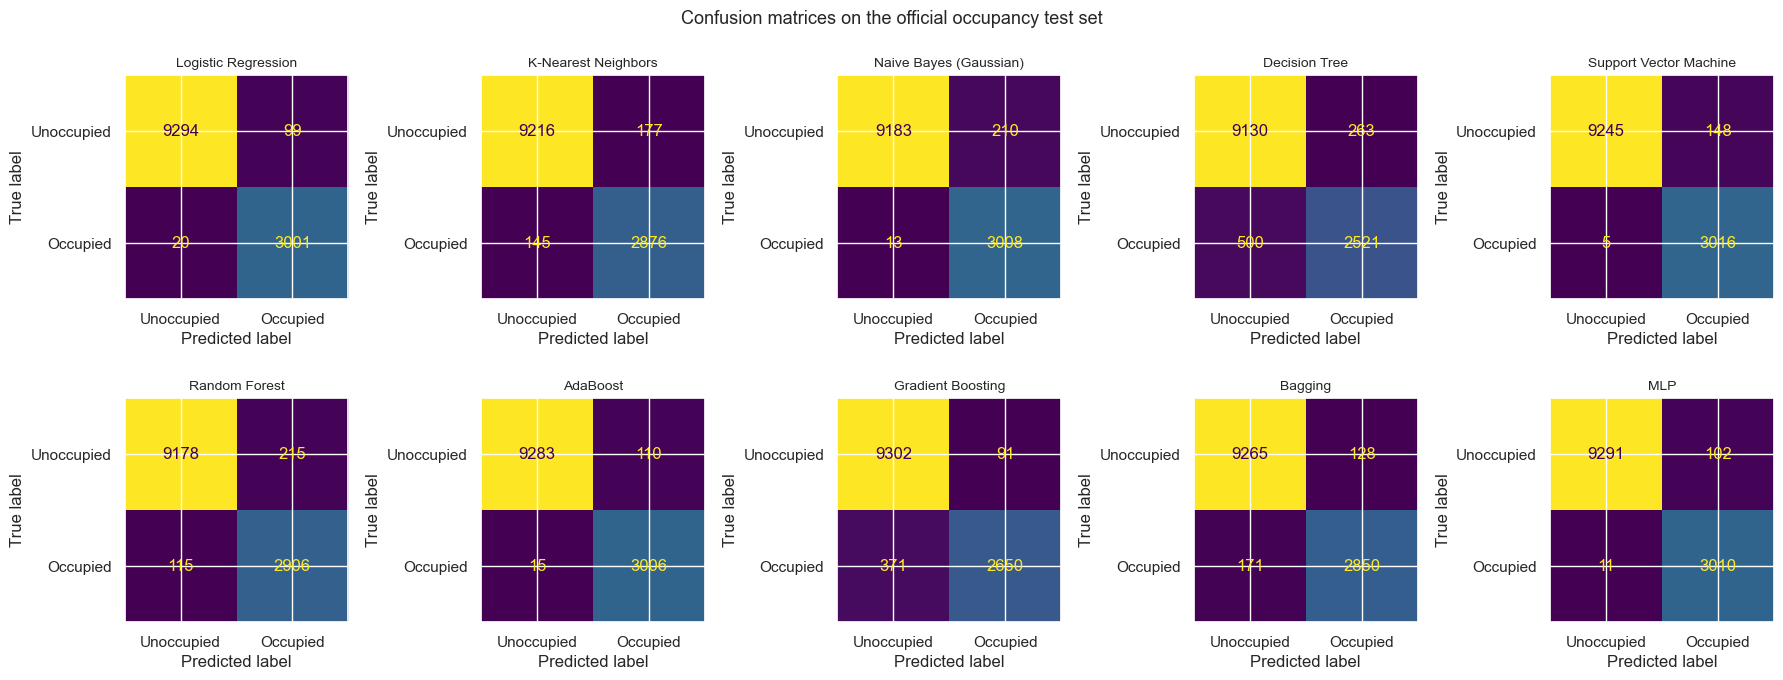

In [6]:
all_models = {}
all_models.update(part_a_models)
all_models.update(tuned_models)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, (name, model) in zip(axes.ravel(), all_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Unoccupied", "Occupied"]).plot(
        ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices on the official occupancy test set", fontsize=13)
fig.tight_layout()
plt.show()


## 6. ROC curves

For the linear SVM, the curve uses decision scores, because that model was fit without class probabilities (same setting as Part A). Every other model uses the predicted probability of the occupied class.


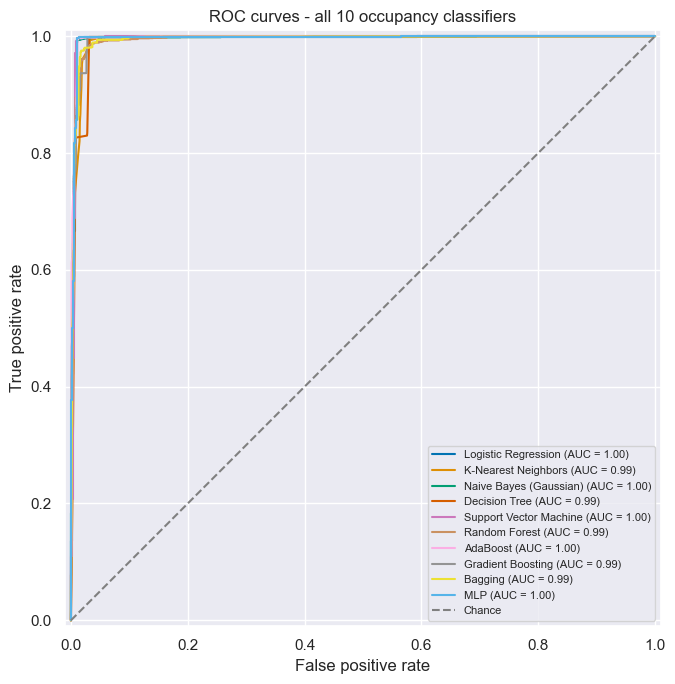

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))
for name, model in all_models.items():
    RocCurveDisplay.from_predictions(
        y_test,
        positive_scores(model, X_test),
        name=name,
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("ROC curves - all 10 occupancy classifiers")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()


## 7. Random Forest feature importance

Importances are from the tuned forest. They describe how often a feature reduced impurity. They are not causal effects, and Light can dominate because lights are switched with occupancy.


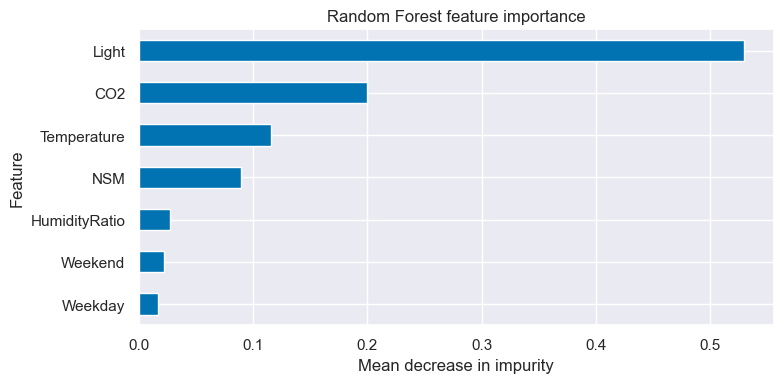

Light            0.5292
CO2              0.1996
Temperature      0.1154
NSM              0.0897
HumidityRatio    0.0272
Weekend          0.0220
Weekday          0.0169
dtype: float64

In [8]:
rf_clf = tuned_models["Random Forest"].named_steps["clf"]
importance = (
    pd.Series(rf_clf.feature_importances_, index=FEATURES)
    .sort_values(ascending=True)
)
fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax, color="C0")
ax.set_title("Random Forest feature importance")
ax.set_xlabel("Mean decrease in impurity")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(4)


### Feature-importance observation

**Observation:** Light accounts for **0.53** of the forest's impurity reduction, then CO2 (**0.20**), Temperature (**0.12**), and seconds-since-midnight (**0.09**). Humidity ratio, Weekend, and Weekday are each under **0.03**. That matches the Part A plots: occupied intervals are the ones with the lights on and higher CO2. Weekend is the complement of Weekday, so those two small importances are one calendar signal split across two columns.


## 8. All ten classifiers

One test-set table. Part B rows are the GridSearch models. Sorted by weighted F1, then ROC-AUC.


In [9]:
rows = []
for name, model in part_a_models.items():
    rows.append(metric_row(name, model, "A"))
for name, model in tuned_models.items():
    rows.append(metric_row(name, model, "B"))

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(["F1", "ROC-AUC", "Accuracy"], ascending=False)
    .reset_index(drop=True)
)
comparison_df.insert(0, "Rank", comparison_df.index + 1)
comparison_df_display = comparison_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    comparison_df_display[col] = comparison_df_display[col].map(lambda v: round(v, 4))
comparison_df_display


,Rank,Track,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,B,MLP,0.9909,0.9911,0.9909,0.9909,0.9959
1,2,A,Logistic Regression,0.9904,0.9906,0.9904,0.9905,0.9951
2,3,B,AdaBoost,0.9899,0.9902,0.9899,0.9900,0.9969
3,4,A,Support Vector Machine,0.9877,0.9882,0.9877,0.9878,0.9953
4,5,A,Naive Bayes (Gaussian),0.9820,0.9830,0.9820,0.9822,0.9957
5,6,B,Bagging,0.9759,0.9758,0.9759,0.9759,0.9942
6,7,A,K-Nearest Neighbors,0.9741,0.9742,0.9741,0.9741,0.9927
7,8,B,Random Forest,0.9734,0.9739,0.9734,0.9736,0.9939
8,9,B,Gradient Boosting,0.9628,0.9629,0.9628,0.9622,0.9943
9,10,A,Decision Tree,0.9385,0.9377,0.9385,0.9377,0.9907


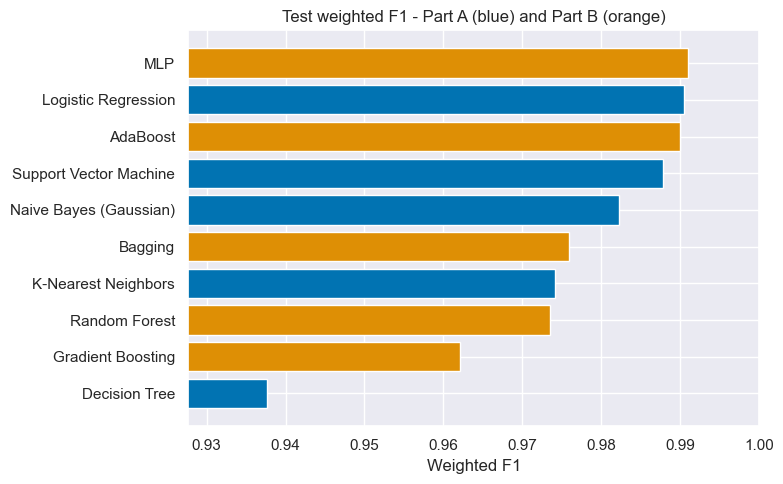

In [10]:
plot_df = comparison_df.sort_values("F1", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["C0" if track == "A" else "C1" for track in plot_df["Track"]]
ax.barh(plot_df["Model"], plot_df["F1"], color=colors)
ax.set_xlim(max(0.90, plot_df["F1"].min() - 0.01), 1.0)
ax.set_xlabel("Weighted F1")
ax.set_title("Test weighted F1 - Part A (blue) and Part B (orange)")
fig.tight_layout()
plt.show()


### Comparison observation (all 10)

**Observation:** Ordered by test weighted F1, the models are **MLP (0.9909)**, **Logistic Regression (0.9905)**, **AdaBoost (0.9900)**, SVM (0.9878), Gaussian NB (0.9822), Bagging (0.9759), KNN (0.9741), Random Forest (0.9738), Gradient Boosting (0.9622), and Decision Tree (0.9377). For the top models, precision and recall stay within about 0.001 of accuracy, so the order is not an artifact of one column. AdaBoost has the highest ROC-AUC (**0.9969**), just ahead of MLP (**0.9959**). Part B does place a new model first, but only by a fraction of a point over the Part A logistic regression.


## 9. Cross-validation of the two best models

Five-fold weighted F1 on the training file only. This is a second check on the two models that lead the test table, as required for each track.


In [11]:
top_two = comparison_df["Model"].head(2).tolist()
cv_rows = []
for name in top_two:
    scores = cross_val_score(
        all_models[name],
        X_train,
        y_train,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
    )
    cv_rows.append({
        "Model": name,
        "CV weighted F1 mean": scores.mean(),
        "CV weighted F1 std": scores.std(),
        "Fold scores": np.round(scores, 4).tolist(),
    })
    print("{:28s}  {:.4f} +/- {:.4f}".format(name, scores.mean(), scores.std()))

cv_df = pd.DataFrame(cv_rows)
cv_df


MLP                           0.9869 +/- 0.0139
Logistic Regression           0.9887 +/- 0.0139


,Model,CV weighted F1 mean,CV weighted F1 std,Fold scores
0,MLP,0.986897,0.013853,"[0.9617, 0.982, 0.9975, 0.9969, 0.9963]"
1,Logistic Regression,0.988664,0.013943,"[0.9617, 0.989, 0.9969, 1.0, 0.9957]"


### Cross-validation observation

**Observation:** Five-fold weighted F1 on the training file is **0.9887 +/- 0.0139** for Logistic Regression and **0.9869 +/- 0.0139** for the MLP. Both dip on the first fold (about **0.962**) and sit near **0.996** on the later folds. Cross-validation therefore ranks logistic regression first, while the official test file ranks the MLP first by **0.0004** F1. The gap is too small to treat as a different conclusion.


In [12]:
best_name = comparison_df.iloc[0]["Model"]
best_model = all_models[best_name]
print("Best model on test weighted F1:", best_name)
print(classification_report(
    y_test,
    best_model.predict(X_test),
    target_names=["Unoccupied", "Occupied"],
    digits=4,
))


Best model on test weighted F1: MLP
              precision    recall  f1-score   support

  Unoccupied     0.9988    0.9891    0.9940      9393
    Occupied     0.9672    0.9964    0.9816      3021

    accuracy                         0.9909     12414
   macro avg     0.9830    0.9927    0.9878     12414
weighted avg     0.9911    0.9909    0.9909     12414



### Selected model

**Observation:** The test-set leader is the tuned MLP: hidden layers **(64, 32)**, ReLU, chosen by 5-fold weighted F1 (CV **0.9869**). Tuning moved its test F1 from **0.9770** to **0.9909**. On the official test file the scores are accuracy **0.9909**, weighted precision **0.9911**, weighted recall **0.9909**, weighted F1 **0.9909**, and ROC-AUC **0.9959**. For occupied intervals, precision is **0.9672** and recall is **0.9964**: the network rarely misses an occupied room, and the leftover mistakes are mostly empty rooms predicted as occupied.

Logistic regression remains the model to mention next to it. Its test F1 is **0.9905**, and its training cross-validation score is slightly higher than the MLP. The two are interchangeable on this sensor set. The table ranks the MLP first because that is the top test-set F1.


## 10. Dimensionality reduction: PCA and LDA pipelines

This is an **additional experiment** alongside the ten required classifiers above. It compares Logistic Regression with all seven original features against Logistic Regression after dimensionality reduction using **PCA** or **LDA**.

- **PCA** is unsupervised: it finds directions that preserve feature variance without using `Occupancy` labels.
- **LDA** is supervised: as a transformer here, it uses the training labels to find a direction that separates the occupancy classes. Since this is a binary problem, LDA can produce at most one discriminant component.
- Each scaler and dimensionality-reduction step lives inside its `Pipeline`. During five-fold cross-validation, those steps are fitted only on each fold's training portion, preventing preprocessing leakage into that fold's validation data.

Grid search uses **weighted F1** on `X_train` / `y_train`. The official held-out test set is used only to report the final comparison after tuning. These experiments do not replace the required ten-model comparison table.

In [13]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Keep the preprocessing consistent with the existing Logistic Regression model.
# The complete Pipeline is refitted independently inside each CV fold.
logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

pca_logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("pca", PCA()),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

lda_logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=1)),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

# With seven input features, PCA components 1-6 actually reduce dimensionality.
pca_component_options = list(range(1, X_train.shape[1]))

pipeline_experiments = {
    "Logistic Regression (all features)": (
        logistic_pipeline,
        {"clf__C": [0.1, 1.0, 10.0]},
    ),
    "PCA + Logistic Regression": (
        pca_logistic_pipeline,
        {
            "pca__n_components": pca_component_options,
            "clf__C": [0.1, 1.0, 10.0],
        },
    ),
    "LDA + Logistic Regression": (
        lda_logistic_pipeline,
        {"clf__C": [0.1, 1.0, 10.0]},
    ),
}

pca_lda_searches = {}
pca_lda_rows = []

for experiment_name, (pipeline, param_grid) in pipeline_experiments.items():
    print("Tuning:", experiment_name)
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    pca_lda_searches[experiment_name] = search

    best_pipeline = search.best_estimator_
    y_pred = best_pipeline.predict(X_test)
    y_prob = best_pipeline.predict_proba(X_test)[:, 1]

    if "pca" in best_pipeline.named_steps:
        reduced_features = best_pipeline.named_steps["pca"].n_components_
    elif "lda" in best_pipeline.named_steps:
        reduced_features = best_pipeline.named_steps["lda"].n_components
    else:
        reduced_features = X_train.shape[1]

    pca_lda_rows.append({
        "Experiment": experiment_name,
        "Original Features": X_train.shape[1],
        "Features After Reduction": reduced_features,
        "Best CV Weighted F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision (weighted)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test Recall (weighted)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test F1 (weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Best Parameters": search.best_params_,
    })

pca_lda_comparison = pd.DataFrame(pca_lda_rows).sort_values(
    "Test F1 (weighted)", ascending=False
).reset_index(drop=True)

# Rounded display table; the underlying DataFrame retains full numeric precision.
pca_lda_display = pca_lda_comparison.copy()
metric_columns = [
    "Best CV Weighted F1",
    "Test Accuracy",
    "Test Precision (weighted)",
    "Test Recall (weighted)",
    "Test F1 (weighted)",
    "Test ROC-AUC",
]
pca_lda_display[metric_columns] = pca_lda_display[metric_columns].round(4)
pca_lda_display

Tuning: Logistic Regression (all features)
Tuning: PCA + Logistic Regression
Tuning: LDA + Logistic Regression


,Experiment,Original Features,Features After Reduction,Best CV Weighted F1,Test Accuracy,Test Precision (weighted),Test Recall (weighted),Test F1 (weighted),Test ROC-AUC,Best Parameters
0,LDA + Logistic Regression,7,1,0.9859,0.9906,0.9908,0.9906,0.9906,0.9948,{'clf__C': 0.1}
1,PCA + Logistic Regression,7,6,0.9887,0.9905,0.9907,0.9905,0.9905,0.9951,"{'clf__C': 10.0, 'pca__n_components': 6}"
2,Logistic Regression (all features),7,7,0.9887,0.9904,0.9906,0.9904,0.9905,0.9951,{'clf__C': 10.0}


### Reading the PCA/LDA results

Use the table above to state which pipeline performs best on the held-out test set, and compare that result with its **training-only cross-validation score**. Do not claim PCA or LDA improves performance unless the measured results support that conclusion. A small test-score difference may not represent a meaningful improvement.

For PCA, the next cell shows the explained-variance ratio of the selected components. This helps describe how much of the feature variance the selected projection retains; it does **not** directly measure how well occupancy classes are separated.

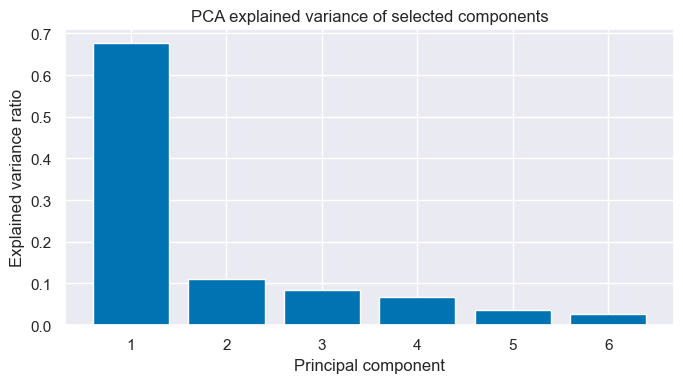

Selected PCA parameters: {'clf__C': 10.0, 'pca__n_components': 6}
Selected PCA components: 6
Total explained variance retained: 1.0000
Selected LDA parameters: {'clf__C': 0.1}


In [14]:
# Inspect the fitted PCA chosen by GridSearchCV.
selected_pca_search = pca_lda_searches["PCA + Logistic Regression"]
selected_pca = selected_pca_search.best_estimator_.named_steps["pca"]
explained_variance = selected_pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 4))
components = np.arange(1, len(explained_variance) + 1)
ax.bar(components, explained_variance)
ax.set_title("PCA explained variance of selected components")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components)
fig.tight_layout()
plt.show()

print("Selected PCA parameters:", selected_pca_search.best_params_)
print("Selected PCA components:", selected_pca.n_components_)
print("Total explained variance retained: {:.4f}".format(explained_variance.sum()))
print("Selected LDA parameters:", pca_lda_searches["LDA + Logistic Regression"].best_params_)